# TOFFEE Purity: Square Index Cutting

The second purity method complements red-noise smoothing (notebook 4) with a shape-based cut: **square index (SI)** measures whether a detected flare is tall and narrow (a real flare) or long and shallow (usually a detrending artifact or instrumental feature). This notebook builds SI up conceptually and visually, covers `add_square_index()` and `select_by_square_index()`, and spends most of its time on `square_index_visualizer()`, the tool built specifically to help you choose a cut by eye rather than guessing a number.

In [1]:
import sys
from pathlib import Path

#temporary until star_toffee is released and pip-installable -- see notebook 1
sys.path.insert(0, str(Path.cwd().parent / 'TOFFEE_upload_claude'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import toffee

## 1. Reload the light curve and detect flares

Same target as notebooks 1-4.

In [2]:
################ TUTORIAL TARGET ################
#change these two values to try a different star/sector
TIC_ID = 84336253
SECTOR = 43

import lightkurve as lk

search_result = lk.search_lightcurve(f'TIC {TIC_ID}', mission = 'TESS', author = 'SPOC',
                                     exptime = 120, sector = SECTOR)
lc = search_result.download()

time = np.asarray(lc.time.value, dtype = float)
flux = np.asarray(lc.flux.value, dtype = float)
flux_err = np.asarray(lc.flux_err.value, dtype = float)

finite = np.isfinite(time) & np.isfinite(flux) & np.isfinite(flux_err)
time, flux, flux_err = time[finite], flux[finite], flux_err[finite]

orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window = 0.25)
flat_flux, flat_flux_err = lc_wotan[0], lc_wotan[1]
quality = np.zeros(len(orbit_time))

flares = toffee.detect_flares(orbit_time, flat_flux, flat_flux_err, quality)
flares

,T_peak,T_start,T_end,Amplitude,ED,Primary_or_Secondary,Num_Points,Num_Abv_Threshold,Amp_Sigma
0,2475.422539,2475.414205,2475.439207,0.296309,333.924647,primary,18,15,10.766277
1,2493.110102,2493.105935,2493.193441,3.026989,5359.732806,primary,64,57,109.984543
2,2493.115658,2493.115658,2493.119825,0.424544,86.751489,secondary,4,4,14.835562


## 2. What square index measures, conceptually

$$\mathrm{SI} = \frac{T_{end} - T_{start}}{\mathrm{Amplitude}}$$

A real flare rises fast and decays within a few times its rise, tall relative to how long it lasts. A detrending artifact (a spot-modulation crest not fully flattened, an orbit-edge ramp, slow instrumental drift) tends to be the opposite: long and shallow, **boxy** rather than spiky. SI is literally the aspect ratio of the box that just encloses the flare (width equal to its duration, height equal to its amplitude):

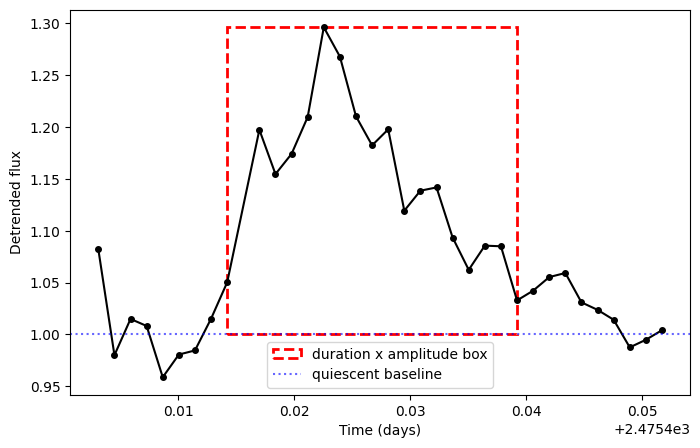

duration = 36.0 minutes, amplitude = 0.2963
SI = duration/amplitude = 0.0844 days
log10(SI) = -1.0738


In [3]:
small_flare = flares.iloc[0]
peak_index = np.where(orbit_time == small_flare['T_peak'])[0][0]
start_index = np.where(orbit_time == small_flare['T_start'])[0][0]
end_index = np.where(orbit_time == small_flare['T_end'])[0][0]

duration = small_flare['T_end'] - small_flare['T_start']
amplitude = small_flare['Amplitude']
pad = 0.5 * duration
window = (orbit_time > small_flare['T_start'] - pad) & (orbit_time < small_flare['T_end'] + pad)

fig, ax = plt.subplots(figsize = (8, 5))
ax.plot(orbit_time[window], flat_flux[window], 'o-', color = 'black', markersize = 4)
#the box: width = duration (T_end - T_start), height = amplitude, sitting on the
#quiescent baseline (flux=1) -- SI is exactly this box's aspect ratio
box = Rectangle((small_flare['T_start'], 1.0), duration, amplitude, fill = False,
                linestyle = '--', edgecolor = 'red', linewidth = 2, label = 'duration x amplitude box')
ax.add_patch(box)
ax.axhline(1.0, color = 'blue', linestyle = ':', alpha = 0.6, label = 'quiescent baseline')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Detrended flux')
ax.legend()
plt.show()

print(f'duration = {duration*1440:.1f} minutes, amplitude = {amplitude:.4f}')
print(f'SI = duration/amplitude = {duration/amplitude:.4f} days')
print(f'log10(SI) = {np.log10(duration/amplitude):.4f}')

A short, tall box (low SI) like this one is what a real flare looks like. Stretch that box out sideways and flatten it (long duration, small amplitude), and log(SI) climbs; that's the boxy shape a purity cut is meant to catch.

## 3. `add_square_index()`: computing it for real

```python
def add_square_index(flares, cadence=120):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `flares` | DataFrame | required | A `detect_flares()` result |
| `cadence` | float | `120` | The light curve's cadence, in **seconds**: `120` for standard 2-minute TESS data, `20` for fast cadence |

Returns a copy of `flares` with four new columns:

| Column | Meaning |
|---|---|
| `Duration` | `T_end - T_start`, in days |
| `Coverage` | Fraction of the `T_start`-`T_end` window actually observed: 1.0 means no gap fell inside it |
| `Log_Square_Index` | `log10(Duration / Amplitude)`, using the *elapsed time* |
| `Log_Square_Index_Obs` | `log10(Num_Points * cadence / Amplitude)`, using the *number of cadences actually observed* instead |

**Why two versions?** A flare whose window happens to straddle a data gap (a momentum dump, a downlink) gets a long *elapsed* duration for free, without its actual shape being boxy at all; that inflates `Log_Square_Index` without the flare being a false positive. `Log_Square_Index_Obs` rebuilds the index from the cadences TOFFEE actually saw instead of elapsed time, so a gap-straddling detection doesn't get penalized for a gap it didn't cause. `Coverage` records which flares those are directly, so they can be found and handled explicitly rather than silently mismeasured.

In [4]:
flares_si = toffee.add_square_index(flares, cadence = 120)
flares_si[['T_peak', 'Amplitude', 'Duration', 'Coverage',
          'Log_Square_Index', 'Log_Square_Index_Obs']]

,T_peak,Amplitude,Duration,Coverage,Log_Square_Index,Log_Square_Index_Obs
0,2475.422539,0.296309,0.025002,0.947285,-1.073764,-1.073805
1,2493.110102,3.026989,0.087506,0.999929,-1.538971,-1.532163
2,2493.115658,0.424544,0.004167,0.999946,-2.008103,-1.883196


## 4. `select_by_square_index()`: cutting a catalogue

```python
def select_by_square_index(catalogue, log_si_min=-np.inf, log_si_max=np.inf,
                           kind=None, column='Log_Square_Index_Obs',
                           min_coverage=None):
```

| Argument | Type | Default | Meaning |
|---|---|---|---|
| `catalogue` | DataFrame | required | A flare frame that has already been through `add_square_index` |
| `log_si_min`, `log_si_max` | float | `-inf`, `inf` | The window to keep, in log10 |
| `kind` | str, list, or `None` | `None` | Restrict to `'primary'`/`'secondary'`/`'tertiary'` (or a list of those), or keep every type |
| `column` | str | `'Log_Square_Index_Obs'` | Which index to cut on: the gap-corrected one by default |
| `min_coverage` | float or `None` | `None` | Also drop flares whose window covers less than this fraction, to remove gap-straddling detections directly |

Returns the rows of `catalogue` that pass every cut.

In [5]:
#keep only reasonably tall, narrow flares -- a permissive cut for illustration
clean = toffee.select_by_square_index(flares_si, log_si_max = 0.6)
print(f'{len(clean)} of {len(flares_si)} flares pass log_si_max=0.6')
clean[['T_peak', 'Amplitude', 'Log_Square_Index_Obs']]

3 of 3 flares pass log_si_max=0.6


,T_peak,Amplitude,Log_Square_Index_Obs
0,2475.422539,0.296309,-1.073805
1,2493.110102,3.026989,-1.532163
2,2493.115658,0.424544,-1.883196


## 5. `square_index_visualizer()`: choosing a cut by eye

This is the tool built specifically for the job: point it at a detrended light curve and a square-index window, and it plots every flare that falls in that window, nothing else. Run it at a few candidate windows and compare what comes back before committing to a cut, the same way `plot_example()` (notebook 4) helps choose `red_noise_smoothing()`'s window length.

| Argument group | Covers |
|---|---|
| Square index selection | `log_si_min`, `log_si_max`, `kind`, `column`, `min_coverage`, `cadence` |
| Already-detected flares | `flares`: hand over a frame you already have to skip detecting twice |
| Lightcurve prep / Detection / Flare modeling / Start-end | every `detect_flares()` argument from notebooks 1-3, used only if `flares` is not given |
| Plotting | `pad_factor`, `plot`, `ncols`, `panel_size`, `fontsize`, colors, `savepath`, `target`, `sector` |

Returns the selected flares (with the square-index columns added), whether or not anything was plotted; pass `plot=False` to just get the selection.

Two real targets from this tutorial series sit at opposite ends of the square-index range found across a small multi-star survey (section 6): **TIC 114029415** at very low SI, **TIC 293968698** at high SI.

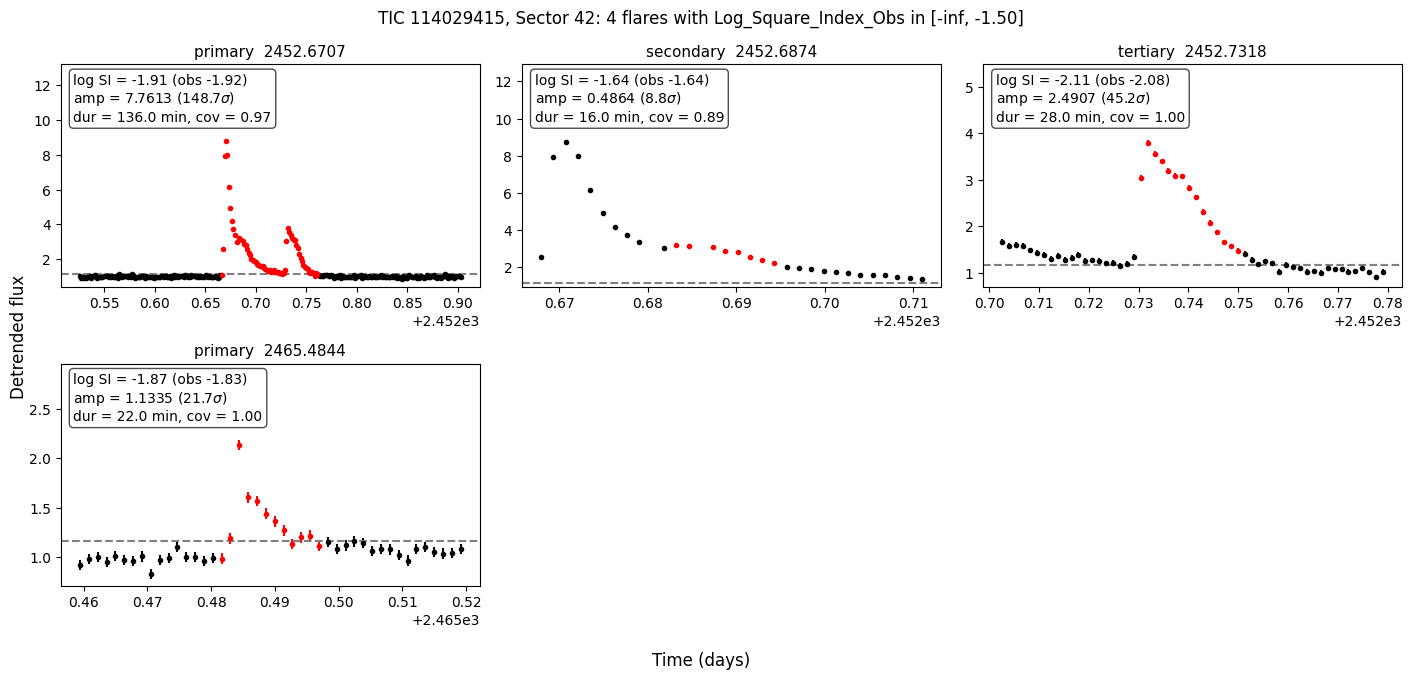

In [6]:
low_si_search = lk.search_lightcurve('TIC 114029415', mission = 'TESS', author = 'SPOC',
                                      exptime = 120, sector = 42)
low_si_lc = low_si_search.download()
low_si_time = np.asarray(low_si_lc.time.value, dtype = float)
low_si_flux = np.asarray(low_si_lc.flux.value, dtype = float)
low_si_flux_err = np.asarray(low_si_lc.flux_err.value, dtype = float)
finite = np.isfinite(low_si_time) & np.isfinite(low_si_flux) & np.isfinite(low_si_flux_err)
low_si_time, low_si_flux, low_si_flux_err = low_si_time[finite], low_si_flux[finite], low_si_flux_err[finite]

low_si_orbit_time, _, low_si_lc_wotan, _ = toffee.flatten(low_si_time, low_si_flux, low_si_flux_err,
                                                          short_window = 0.25)
low_si_flat_flux, low_si_flat_flux_err = low_si_lc_wotan[0], low_si_lc_wotan[1]
low_si_quality = np.zeros(len(low_si_orbit_time))

low_si_selection = toffee.square_index_visualizer(low_si_orbit_time, low_si_flat_flux,
                                                  low_si_flat_flux_err, low_si_quality,
                                                  log_si_max = -1.5, target = 114029415, sector = 42)

Every one of these is a sharp, fast spike, including the overlapping primary/secondary pair from notebook 3. Now a target with several flares at the **high** end of the range:

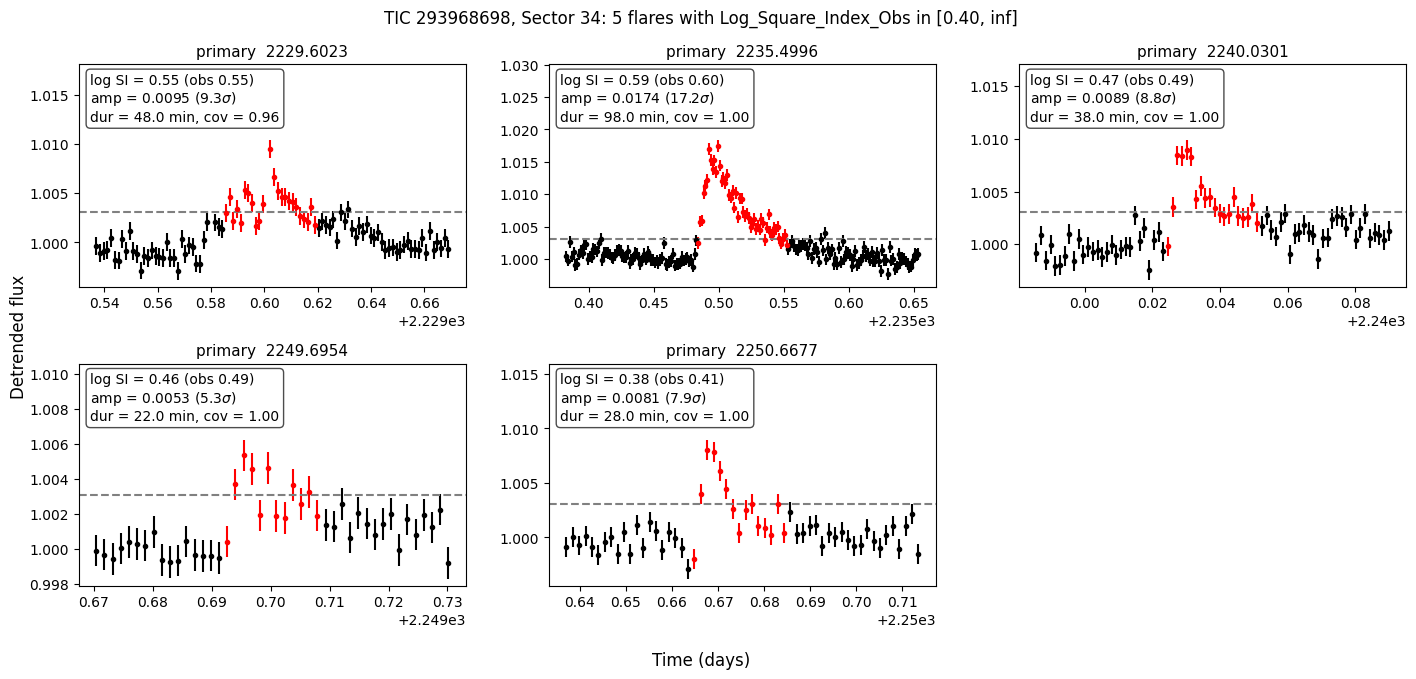

In [7]:
high_si_search = lk.search_lightcurve('TIC 293968698', mission = 'TESS', author = 'SPOC',
                                       exptime = 120, sector = 34)
high_si_lc = high_si_search.download()
high_si_time = np.asarray(high_si_lc.time.value, dtype = float)
high_si_flux = np.asarray(high_si_lc.flux.value, dtype = float)
high_si_flux_err = np.asarray(high_si_lc.flux_err.value, dtype = float)
finite = np.isfinite(high_si_time) & np.isfinite(high_si_flux) & np.isfinite(high_si_flux_err)
high_si_time, high_si_flux, high_si_flux_err = (high_si_time[finite], high_si_flux[finite],
                                                high_si_flux_err[finite])

high_si_orbit_time, _, high_si_lc_wotan, _ = toffee.flatten(high_si_time, high_si_flux,
                                                            high_si_flux_err, short_window = 0.25)
high_si_flat_flux, high_si_flat_flux_err = high_si_lc_wotan[0], high_si_lc_wotan[1]
high_si_quality = np.zeros(len(high_si_orbit_time))

high_si_selection = toffee.square_index_visualizer(high_si_orbit_time, high_si_flat_flux,
                                                    high_si_flat_flux_err, high_si_quality,
                                                    log_si_min = 0.4, target = 293968698, sector = 34)

Five flares, all with high coverage (so this isn't a gap-straddling artifact), and all clearly slower and more rounded than the low-SI panel above: rising and falling over 20-100 minutes with amplitudes of a fraction of a percent, rather than the fast, sharp spikes on the other end. Whether these are genuine (if unusually gradual) flares or residual modulation depends on the star and needs a human judgment call, which is exactly why this tool exists: to put the actual shapes in front of you at whatever window you're considering, rather than picking a cut number in the abstract.

## 6. Where to put the cut: a small multi-star survey

One star's worth of flares isn't enough to see the overall shape of the square-index distribution: the same catalogue-scale point notebook 4 made about `lightcurve_quality`. Here are all the flares from the targets used across this tutorial series, combined into one catalogue:

In [8]:
survey_targets = [
    (84336253, 43), (114029415, 42), (70744265, 2), (293968698, 34),
    (308542808, 8), (167344029, 36), (286122000, 58), (382043650, 13),
    (348638902, 44),
]

survey_rows = []
for tic, sector in survey_targets:
    search_result = lk.search_lightcurve(f'TIC {tic}', mission = 'TESS', author = 'SPOC',
                                         exptime = 120, sector = sector)
    survey_lc = search_result.download()
    survey_time = np.asarray(survey_lc.time.value, dtype = float)
    survey_flux = np.asarray(survey_lc.flux.value, dtype = float)
    survey_flux_err = np.asarray(survey_lc.flux_err.value, dtype = float)
    finite = np.isfinite(survey_time) & np.isfinite(survey_flux) & np.isfinite(survey_flux_err)
    survey_time, survey_flux, survey_flux_err = (survey_time[finite], survey_flux[finite],
                                                 survey_flux_err[finite])

    survey_orbit_time, _, survey_lc_wotan, _ = toffee.flatten(survey_time, survey_flux,
                                                              survey_flux_err, short_window = 0.25)
    survey_flat_flux, survey_flat_flux_err = survey_lc_wotan[0], survey_lc_wotan[1]
    survey_quality = np.zeros(len(survey_orbit_time))

    survey_flares = toffee.detect_flares(survey_orbit_time, survey_flat_flux,
                                         survey_flat_flux_err, survey_quality)
    survey_flares = toffee.add_square_index(survey_flares, cadence = 120)
    survey_flares['TIC'] = tic
    survey_rows.append(survey_flares)

survey_catalogue = pd.concat(survey_rows, ignore_index = True)
print(f'{len(survey_catalogue)} flares total across {len(survey_targets)} targets')
survey_catalogue['Log_Square_Index_Obs'].describe()

78 flares total across 9 targets


count    78.000000
mean     -0.211970
std       0.620533
min      -2.077555
25%      -0.374864
50%      -0.050311
75%       0.168759
max       0.600705
Name: Log_Square_Index_Obs, dtype: float64

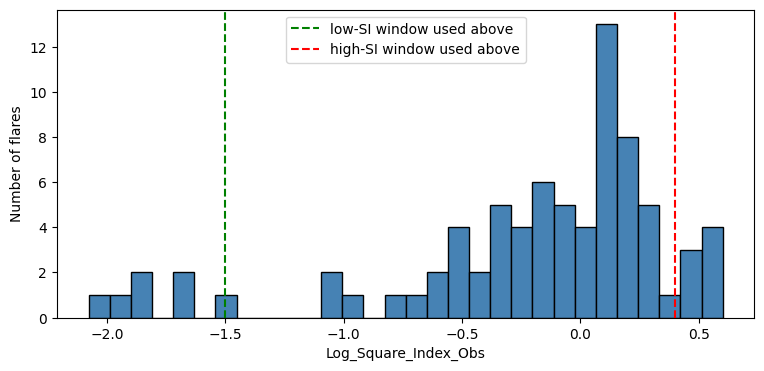

In [9]:
fig, ax = plt.subplots(figsize = (9, 4))
ax.hist(survey_catalogue['Log_Square_Index_Obs'], bins = 30, color = 'steelblue', edgecolor = 'black')
ax.axvline(-1.5, color = 'green', linestyle = '--', label = 'low-SI window used above')
ax.axvline(0.4, color = 'red', linestyle = '--', label = 'high-SI window used above')
ax.set_xlabel('Log_Square_Index_Obs')
ax.set_ylabel('Number of flares')
ax.legend()
plt.show()

Only 9 stars, so this is a shape to read qualitatively, not a cut to read off precisely, but the two windows visualized above sit right at its two ends, which is exactly why they made such a clear contrast. A real catalogue-scale cut needs many more targets and, per the section below, its own visual check with `square_index_visualizer` at whatever boundary looks reasonable here.

## 7. Five square-index ranges, sampled from a real catalogue

9 stars isn't enough to fill out the boxy end of the square-index axis: the survey above found exactly one flare above log SI = 0.6 and none above 0.8. The tool in section 8 below exists for exactly this: point it at a much bigger, already-detected flare catalogue and its matching local light curve files, and pull real, representative examples from any square-index window on demand.

This machine happens to have both: a 19,422-flare TOFFEE catalogue (`Flares_30_08_2025_Feinstein.csv`, from earlier project work) and the 9,273 SPOC light curve files it was detected from. That's exactly the local setup section 8 describes, so rather than leave the tool as a pure reference, here it is actually run, with its two path constants corrected for where those files live in this checkout. **This part is not portable**: it needs those specific local files, which is exactly the caveat section 8 raises, and is why the rest of this tutorial never depends on it.

In [10]:
FEINSTEIN_CATALOGUE_PATH = ('/Users/jasonreeves/Documents/TOFFEE/Sympathetic_Flaring/'
                            'Flare_Catalogs/Flares_30_08_2025_Feinstein.csv')
FEINSTEIN_LC_PATH = ('/Users/jasonreeves/Documents/TOFFEE/Sympathetic_Flaring/Stars_Data/'
                     'SPOC_Lightcurve_Feinstein_Sectors/')
FEINSTEIN_CADENCE = 2.0 / (24 * 60)   # SPOC 2 minute cadence, in days

import os
import re
import glob

#same load_catalogue() from section 8, just called on the real path above
feinstein_catalogue = pd.read_csv(FEINSTEIN_CATALOGUE_PATH, index_col = 0)
feinstein_catalogue['TIC'] = feinstein_catalogue['TIC'].astype(int)
feinstein_catalogue = toffee.add_square_index(feinstein_catalogue, cadence = 120)

print(f'{len(feinstein_catalogue)} flares, {feinstein_catalogue["TIC"].nunique()} stars')
feinstein_catalogue['Log_Square_Index_Obs'].describe()

19422 flares, 2269 stars


count    19422.000000
mean        -0.362262
std          0.639882
min         -3.331038
25%         -0.800180
50%         -0.315811
75%          0.118236
max          1.813550
Name: Log_Square_Index_Obs, dtype: float64

In [11]:
#same find_sector() / load_detrended() / plot_flare() / plot_flare_grid() from section 8,
#with FEINSTEIN_LC_PATH baked in directly instead of read from a module-level default

_feinstein_range_cache = {}
_feinstein_flat_cache = {}

def feinstein_file_time_range(name):
    if name not in _feinstein_range_cache:
        with open(os.path.join(FEINSTEIN_LC_PATH, name)) as f:
            times = np.array(f.readline().split(','), dtype = float)
        _feinstein_range_cache[name] = (np.nanmin(times), np.nanmax(times))
    return _feinstein_range_cache[name]

def feinstein_find_sector(tic, t_peak):
    files = sorted(glob.glob(os.path.join(FEINSTEIN_LC_PATH, 'SPOC_Light_Curves_%d_*.csv' % int(tic))))
    for path in files:
        name = os.path.basename(path)
        t_first, t_last = feinstein_file_time_range(name)
        if t_first <= t_peak <= t_last:
            return name, int(re.findall(r'(\d+)', name)[1])
    return None, None

def feinstein_load_detrended(tic, sector):
    key = (int(tic), int(sector))
    if key in _feinstein_flat_cache:
        return _feinstein_flat_cache[key]
    name = 'SPOC_Light_Curves_%d_%d.csv' % (int(tic), int(sector))
    light_curve = np.genfromtxt(os.path.join(FEINSTEIN_LC_PATH, name), delimiter = ',')
    time, flux, quality, flux_err = light_curve[0], light_curve[1], light_curve[2], light_curve[3]
    good = quality == 0
    flux = flux[good]
    time = time[good][~np.isnan(flux)]
    flux_err = flux_err[good][~np.isnan(flux)]
    flux = flux[~np.isnan(flux)]
    orbit_time, _, lc_wotan, _ = toffee.flatten(time, flux, flux_err, short_window = 0.25)
    result = (orbit_time, lc_wotan[0], lc_wotan[1])
    _feinstein_flat_cache[key] = result
    return result

def feinstein_plot_flare(flare, ax, pad_factor = 1.5):
    tic, t_peak = int(flare['TIC']), flare['T_peak']
    name, sector = feinstein_find_sector(tic, t_peak)
    if name is None:
        ax.text(0.5, 0.5, 'TIC %d\nno local sector for t=%.3f' % (tic, t_peak),
               ha = 'center', va = 'center', transform = ax.transAxes, fontsize = 8)
        return
    time, flux, flux_err = feinstein_load_detrended(tic, sector)
    duration = flare['T_end'] - flare['T_start']
    pad = pad_factor * duration
    window = (time > flare['T_start'] - pad) & (time < flare['T_end'] + pad)
    flare_pts = (time >= flare['T_start']) & (time <= flare['T_end'])
    ax.plot(time[window & ~flare_pts], flux[window & ~flare_pts], '.', color = 'black', markersize = 3)
    ax.plot(time[window & flare_pts], flux[window & flare_pts], '.', color = 'red', markersize = 3)
    ax.set_title('TIC %d  S%d  %s\nlog SI(obs) = %.2f' %
                 (tic, sector, flare['Primary_or_Secondary'], flare['Log_Square_Index_Obs']),
                 fontsize = 8)

def feinstein_plot_grid(selection, ncols = 4, panel_size = (4.0, 3.0), suptitle = None):
    n = len(selection)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize = (panel_size[0] * ncols, panel_size[1] * nrows))
    axs = np.atleast_1d(axs).ravel()
    for ax, (_, flare) in zip(axs, selection.iterrows()):
        feinstein_plot_flare(flare, ax)
    for ax in axs[n:]:
        ax.axis('off')
    if suptitle is not None:
        fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()

For each range: select every flare that falls in it (dropping anything with `Coverage < 0.6`, the gap-straddling cut from section 3), then show up to 12, drawn at random so the panels are representative rather than clustered on whichever star happens to sort first.

2207 flares in [0.0, 0.2) with coverage >= 0.6


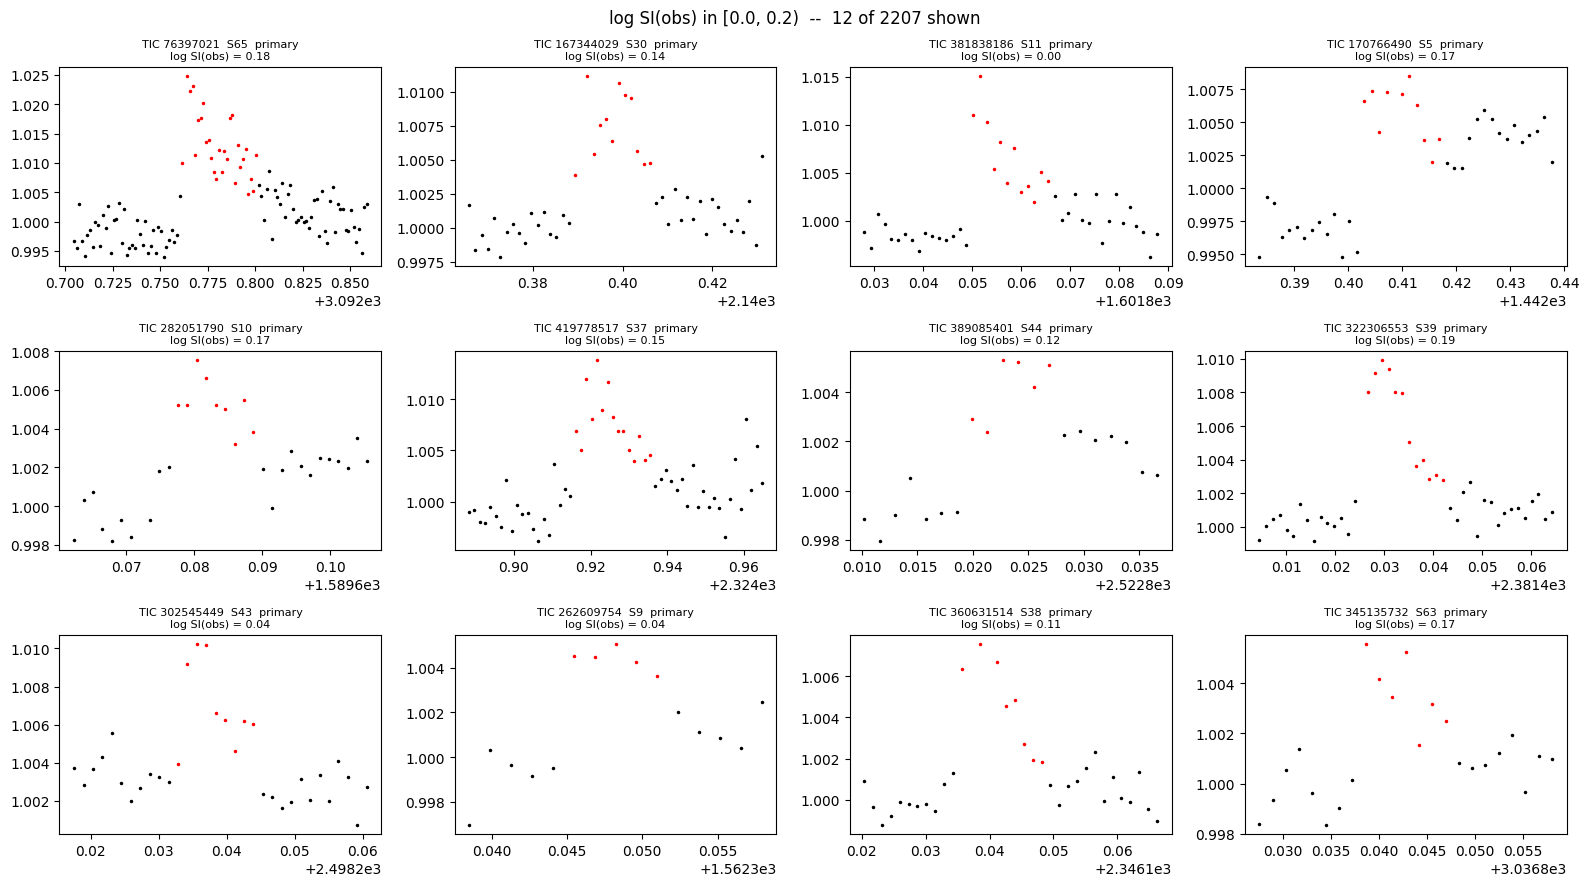

In [12]:
window = feinstein_catalogue[(feinstein_catalogue['Log_Square_Index_Obs'] >= 0.0) &
                             (feinstein_catalogue['Log_Square_Index_Obs'] < 0.2) &
                             (feinstein_catalogue['Coverage'] >= 0.6)]
print(f'{len(window)} flares in [0.0, 0.2) with coverage >= 0.6')
shown = window if len(window) <= 12 else window.sample(12, random_state = 3)
feinstein_plot_grid(shown, suptitle = f'log SI(obs) in [0.0, 0.2)  --  {len(shown)} of {len(window)} shown')

1839 flares in [0.2, 0.4) with coverage >= 0.6


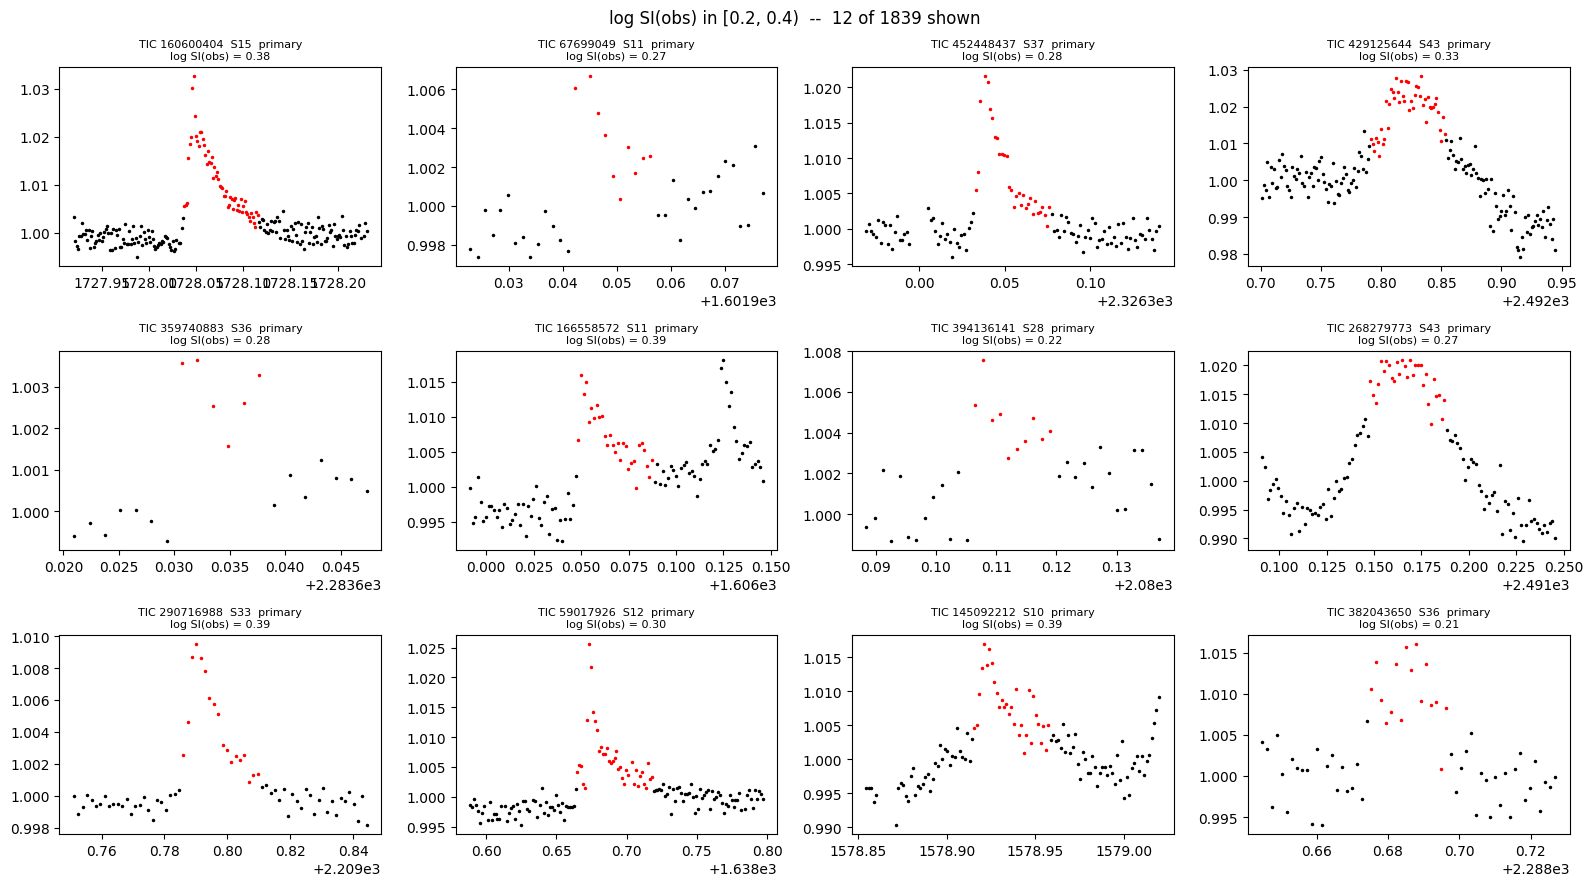

In [13]:
window = feinstein_catalogue[(feinstein_catalogue['Log_Square_Index_Obs'] >= 0.2) &
                             (feinstein_catalogue['Log_Square_Index_Obs'] < 0.4) &
                             (feinstein_catalogue['Coverage'] >= 0.6)]
print(f'{len(window)} flares in [0.2, 0.4) with coverage >= 0.6')
shown = window if len(window) <= 12 else window.sample(12, random_state = 3)
feinstein_plot_grid(shown, suptitle = f'log SI(obs) in [0.2, 0.4)  --  {len(shown)} of {len(window)} shown')

1168 flares in [0.4, 0.6) with coverage >= 0.6


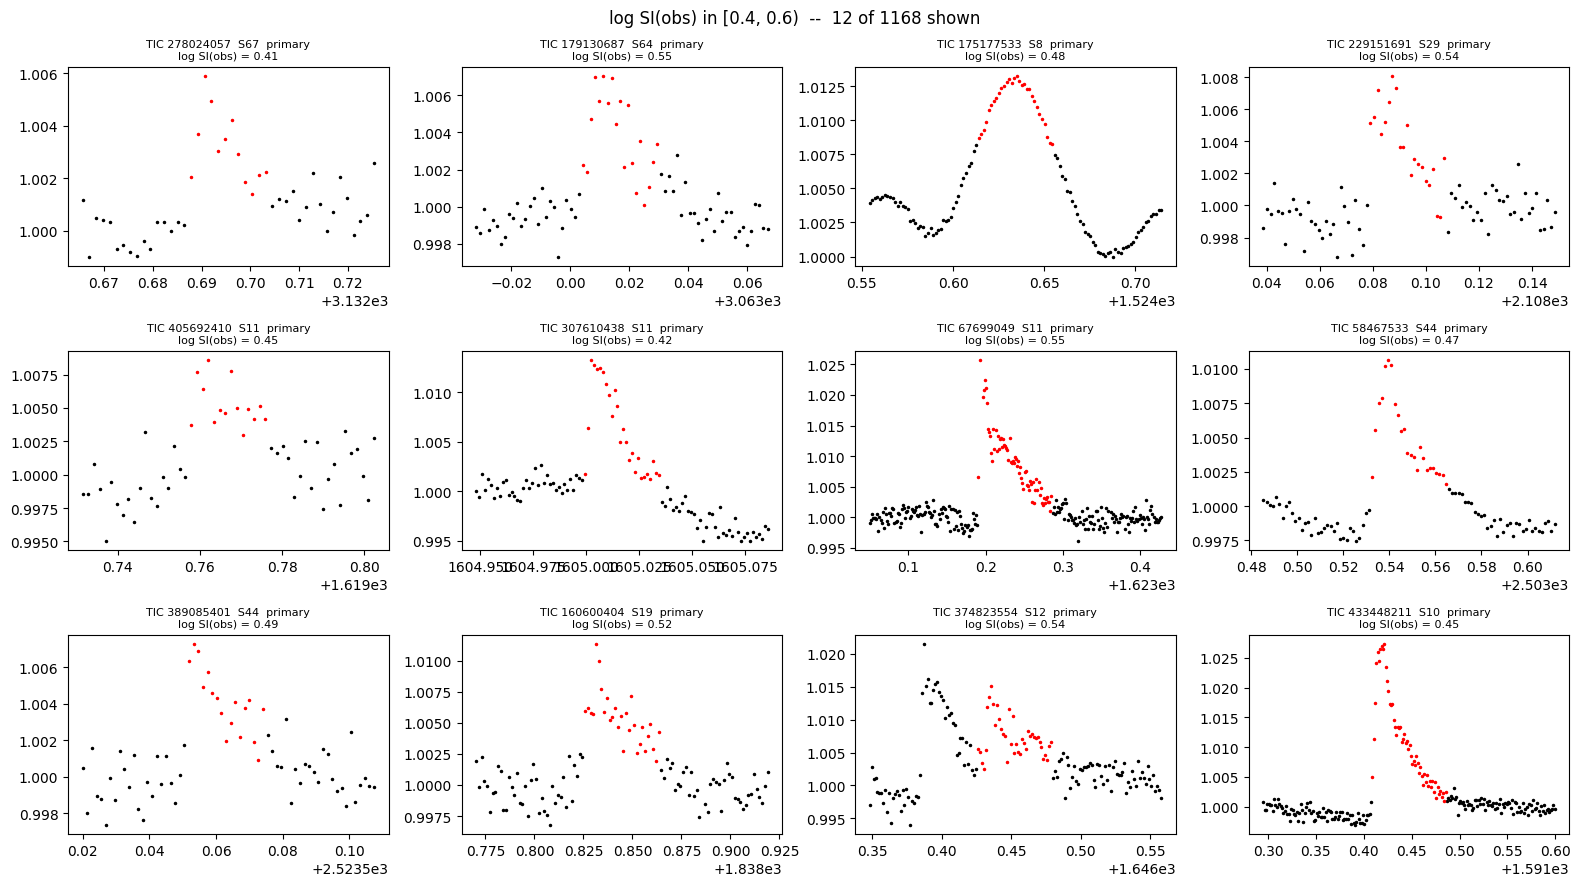

In [14]:
window = feinstein_catalogue[(feinstein_catalogue['Log_Square_Index_Obs'] >= 0.4) &
                             (feinstein_catalogue['Log_Square_Index_Obs'] < 0.6) &
                             (feinstein_catalogue['Coverage'] >= 0.6)]
print(f'{len(window)} flares in [0.4, 0.6) with coverage >= 0.6')
shown = window if len(window) <= 12 else window.sample(12, random_state = 3)
feinstein_plot_grid(shown, suptitle = f'log SI(obs) in [0.4, 0.6)  --  {len(shown)} of {len(window)} shown')

Here you can see a mild mix of good complex flares and false positives such as the gaussian looking bump. For me this is about where I draw the line, making a cut and keeping all flares with log(SI) < 0.6 and get <20% contamination or so in this bin.

649 flares in [0.6, 0.8) with coverage >= 0.6


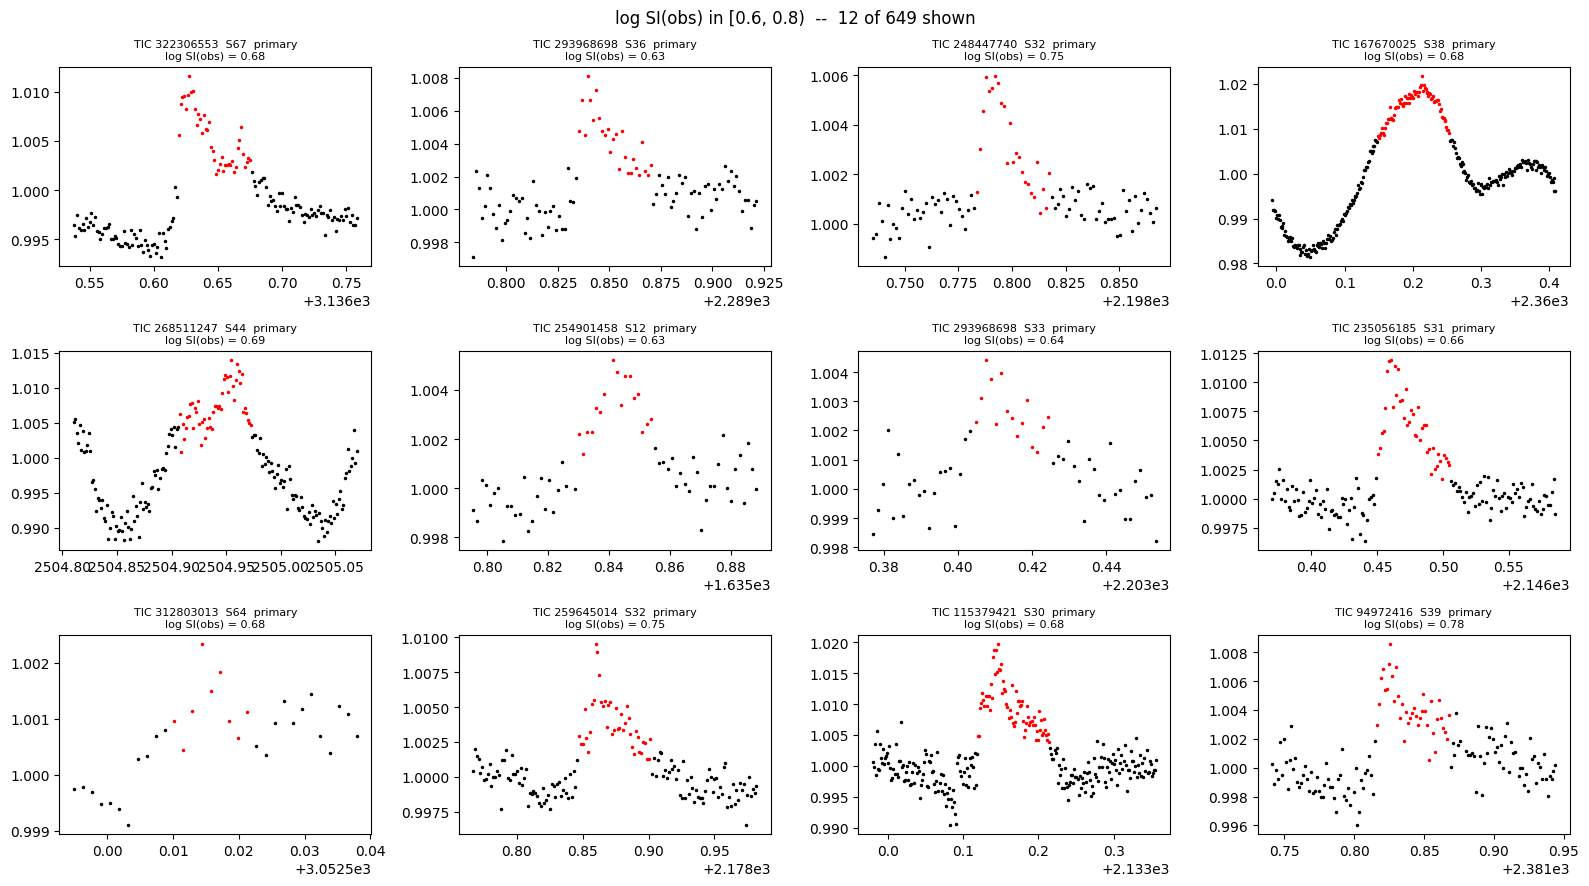

In [15]:
window = feinstein_catalogue[(feinstein_catalogue['Log_Square_Index_Obs'] >= 0.6) &
                             (feinstein_catalogue['Log_Square_Index_Obs'] < 0.8) &
                             (feinstein_catalogue['Coverage'] >= 0.6)]
print(f'{len(window)} flares in [0.6, 0.8) with coverage >= 0.6')
shown = window if len(window) <= 12 else window.sample(12, random_state = 3)
feinstein_plot_grid(shown, suptitle = f'log SI(obs) in [0.6, 0.8)  --  {len(shown)} of {len(window)} shown')

One characteristic to point out is in the first and last flare shown in the plot. Notice that the quiescent background demonstrates this linear decrease in normailzed flux going well below the expected value of 1. It then shoots up rapidly forming a flare detection. To me this resembles some kind of detrending/processing issue that breaks the lightcurve rather than a true flare signal. They also often feature a more linear decay rather than exponential decay which increases the square index value. I'm happy to throw these out as false-positive detection. We really want to see clean, flat quiescent backgrounds before the flare signal, anything else raises a red flag that it's a false positive. I do think SOME of these are true positives including the second snf fifth detection but to my eye this array represents >50% contamination.

I want to stress that the vast majority of flares have square indices of less than 1 so these all represent rare objects. Even without the quality cut flare purity is ~90% as shown by the total distribution of SI's from the Feinstein sample:

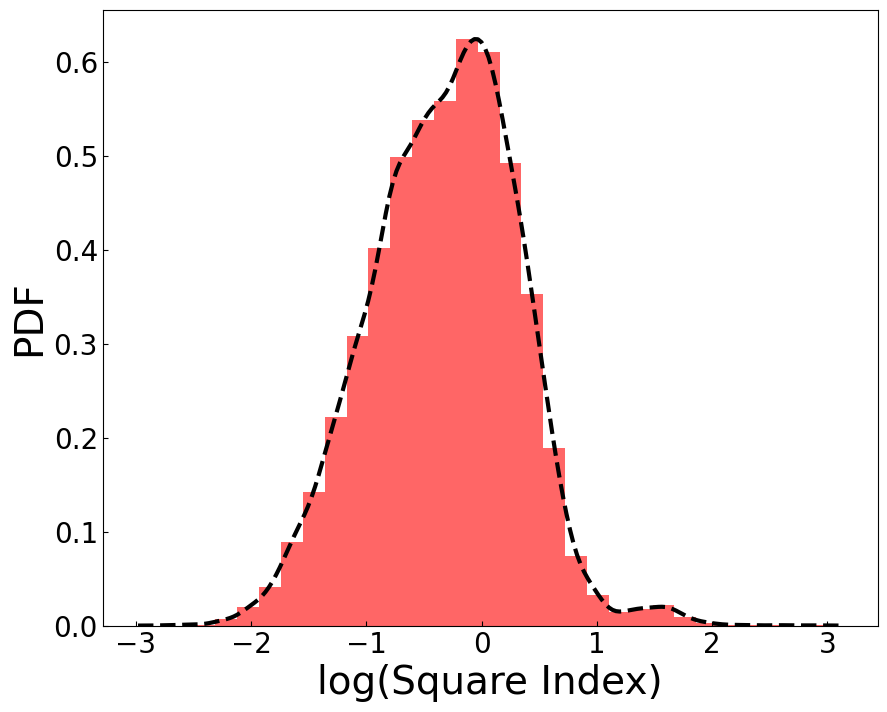

Integrating this curve from 0.6 to 3.0 (including the bump coming from detections straddling the break) gets 0.11. 11% of raw flare detections are iffy.

302 flares in [0.8, inf) with coverage >= 0.6


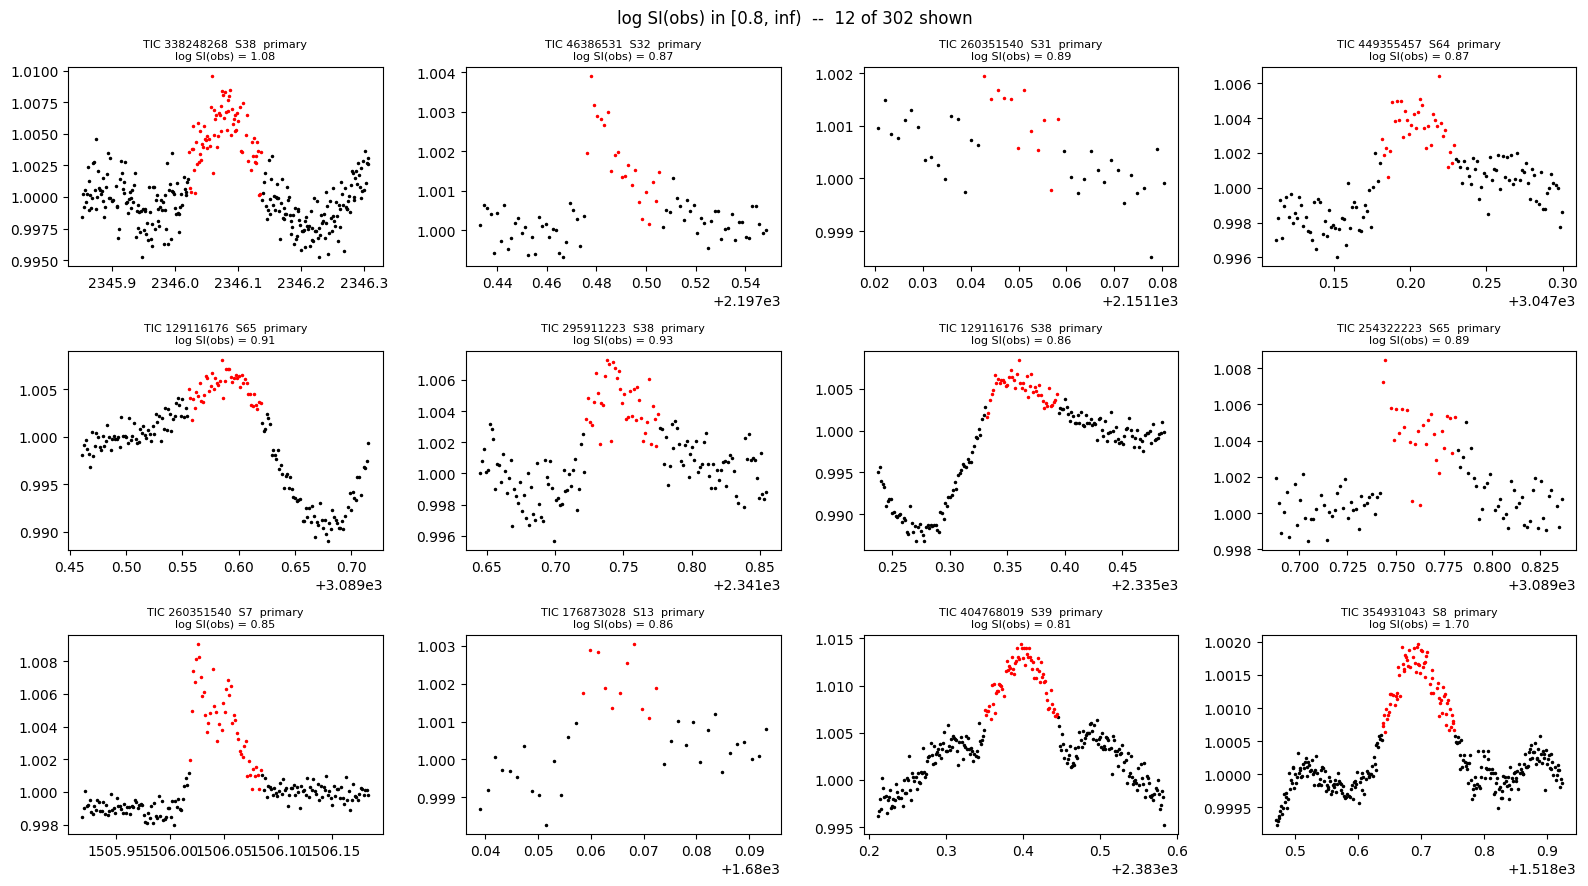

In [16]:
window = feinstein_catalogue[(feinstein_catalogue['Log_Square_Index_Obs'] >= 0.8) &
                             (feinstein_catalogue['Log_Square_Index_Obs'] < np.inf) &
                             (feinstein_catalogue['Coverage'] >= 0.6)]
print(f'{len(window)} flares in [0.8, inf) with coverage >= 0.6')
shown = window if len(window) <= 12 else window.sample(12, random_state = 3)
feinstein_plot_grid(shown, suptitle = f'log SI(obs) in [0.8, inf)  --  {len(shown)} of {len(window)} shown')

The progression across the five grids is the whole point of the method made visible: the low end is essentially all sharp, fast, single-cadence-rise spikes; by the last window (log SI(obs) > 0.8) almost everything left is a slow, rounded bump, a ramp at an orbit edge, or a piece of residual spot-modulation crossing the detection threshold, shapes that look nothing like a flare once they're actually in front of you. That's why the cut works: it's separating two visually distinct populations, not drawing an arbitrary line through one continuous one.

## 8. Scaling up: sampling a whole local catalogue

Everything above works on one already-loaded light curve at a time. Building the figures used to actually pick the cuts in this method (comparing dozens of real, random flares at a given square-index range, across an entire catalogue of pre-detected flares) used a separate, local-file-based tool, included here as reference, **not executable in this notebook**, since it depends on files that only exist on the machine that built the catalogue.

**What it needs from you:** a flare catalogue CSV (from running `detect_flares()` + `add_square_index()` over every light curve you care about and concatenating the results, as in section 6 but at real scale), plus every light curve saved locally as its own file, named so the TIC and sector can be recovered from the filename: here, `SPOC_Light_Curves_<TIC>_<sector>.csv`, one row each for time/flux/quality/flux_err. Once that convention is in place, the functions below search it directly: give a catalogue row's TIC and peak time, and `find_sector` locates the right file by checking which one's time coverage contains that peak: no need to already know which sector a given flare came from.

```python
# square_index.py: catalogue and local file lookup

CATALOGUE_PATH = '/path/to/your_flare_catalogue.csv'
LC_PATH = '/path/to/your_saved_lightcurves/'
CADENCE = 2.0 / (24 * 60)   # SPOC 2 minute cadence, in days

def load_catalogue(path=CATALOGUE_PATH):
    # Adds the duration and square index columns to the raw catalogue CSV.
    cat = pd.read_csv(path, index_col=0)
    cat['TIC'] = cat['TIC'].astype(int)
    cat['Duration'] = cat['T_end'] - cat['T_start']
    cat['Square_Index'] = cat['Duration'] / cat['Amplitude']
    cat['Log_Square_Index'] = np.log10(cat['Square_Index'])
    cat['Coverage'] = cat['Num_Points'] / (cat['Duration'] / CADENCE + 1)
    cat['Obs_Duration'] = cat['Num_Points'] * CADENCE
    cat['Square_Index_Obs'] = cat['Obs_Duration'] / cat['Amplitude']
    cat['Log_Square_Index_Obs'] = np.log10(cat['Square_Index_Obs'])
    return cat


def sample_by_square_index(cat, log_si_min=-np.inf, log_si_max=np.inf,
                           n=12, kind=None, column='Log_Square_Index',
                           min_coverage=None, seed=42):
    # Random draw from a square index window, so a panel grid is representative
    # of the window instead of being the first N rows (which cluster by target).
    mask = (cat[column] >= log_si_min) & (cat[column] <= log_si_max)
    if kind is not None:
        kinds = [kind] if isinstance(kind, str) else list(kind)
        mask = mask & cat['Primary_or_Secondary'].isin(kinds)
    if min_coverage is not None:
        mask = mask & (cat['Coverage'] >= min_coverage)
    sel = cat[mask]
    if n is not None and len(sel) > n:
        sel = sel.sample(n=n, random_state=seed)
    return sel.sort_values(column)
```

```python
# square_index.py: local light curve lookup by TIC + peak time

_range_cache = {}   # filename -> (t_first, t_last)
_flat_cache = {}    # (TIC, sector) -> (time, flux, flux_err, flux_std)

def _file_time_range(name):
    # First row of the file is the time array, so the coverage is one readline.
    if name not in _range_cache:
        with open(os.path.join(LC_PATH, name)) as f:
            times = np.array(f.readline().split(','), dtype=float)
        _range_cache[name] = (np.nanmin(times), np.nanmax(times))
    return _range_cache[name]


def find_sector(tic, t_peak, lc_path=LC_PATH):
    # Returns (filename, sector) of the light curve covering t_peak, or
    # (None, None) if no downloaded sector for this target contains it.
    files = sorted(glob.glob(os.path.join(lc_path,
                                          'SPOC_Light_Curves_%d_*.csv' % int(tic))))
    for path in files:
        name = os.path.basename(path)
        t_first, t_last = _file_time_range(name)
        if t_first <= t_peak <= t_last:
            return name, int(re.findall(r'(\d+)', name)[1])
    return None, None


def load_detrended(tic, sector=None, t_peak=None, lc_path=LC_PATH, use_cache=True):
    # Returns (time, flux, flux_err, flux_std) of the detrended light curve,
    # looking up the sector from t_peak if it is not given directly.
    if sector is None:
        name, sector = find_sector(tic, t_peak, lc_path=lc_path)
        if name is None:
            raise FileNotFoundError('No downloaded sector covers TIC %d at t=%.4f'
                                    % (int(tic), t_peak))
    else:
        name = 'SPOC_Light_Curves_%d_%d.csv' % (int(tic), int(sector))

    key = (int(tic), int(sector))
    if use_cache and key in _flat_cache:
        return _flat_cache[key]

    light_curve = np.genfromtxt(os.path.join(lc_path, name), delimiter=',')
    time, flux, quality, flux_err = light_curve[0], light_curve[1], light_curve[2], light_curve[3]
    perfect_points = quality == 0
    flux = flux[perfect_points]
    time = time[perfect_points][np.isnan(flux) == False]
    flux_err = flux_err[perfect_points][np.isnan(flux) == False]
    flux = flux[np.isnan(flux) == False]

    orbit_time, lc_quad, lc_wotan, periodic = toffee.flatten(time, flux, flux_err, short_window=0.25)
    time, flux, flux_err = orbit_time, lc_wotan[0], lc_wotan[1]
    flux_std = np.nanpercentile(flux - 1, 84)

    result = (time, flux, flux_err, flux_std)
    if use_cache:
        _flat_cache[key] = result
    return result
```

```python
# square_index.py: plotting one flare, and a grid of many

def plot_flare(flare, ax=None, pad_factor=1.5, threshold=3.0, fontsize=9):
    # Plots one catalogue row on its own light curve, background points in black
    # and the TOFFEE-identified flare points in red: flare is one row (a Series)
    # of a catalogue built with load_catalogue.
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(6, 4))

    tic, t_peak = int(flare['TIC']), flare['T_peak']
    name, sector = find_sector(tic, t_peak)
    if name is None:
        ax.text(0.5, 0.5, 'TIC %d\nno sector file for t=%.3f' % (tic, t_peak),
                ha='center', va='center', transform=ax.transAxes, fontsize=fontsize)
        return ax

    time, flux, flux_err, flux_std = load_detrended(tic, sector=sector)
    duration = flare['T_end'] - flare['T_start']
    pad = pad_factor * duration
    window = (time > flare['T_start'] - pad) & (time < flare['T_end'] + pad)
    flare_pts = (time >= flare['T_start']) & (time <= flare['T_end'])

    ax.errorbar(time[window & ~flare_pts], flux[window & ~flare_pts],
                flux_err[window & ~flare_pts], fmt='.', color='black')
    ax.errorbar(time[window & flare_pts], flux[window & flare_pts],
                flux_err[window & flare_pts], fmt='.', color='red')
    ax.axhline(1 + threshold * flux_std, color='grey', linestyle='--')
    ax.set_title('TIC %d  S%d  %s' % (tic, sector, flare['Primary_or_Secondary']),
                 fontsize=fontsize + 1)
    label = ('log SI = %.2f\namp = %.3f (%.1f sigma)\ndur = %.1f min'
             % (flare['Log_Square_Index'], flare['Amplitude'],
                flare['Amp_Sigma'], duration * 24 * 60))
    ax.text(0.03, 0.96, label, transform=ax.transAxes, ha='left', va='top',
            fontsize=fontsize, bbox=dict(boxstyle='round', fc='white', alpha=0.7))
    return ax


def plot_flare_grid(sel, ncols=3, panel_size=(4.6, 3.4)):
    # sel is a catalogue subset, e.g. from sample_by_square_index. Plots every
    # flare in it on a grid, one panel each, pulling each one's own light curve.
    n = len(sel)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(panel_size[0]*ncols, panel_size[1]*nrows))
    axs = np.atleast_1d(axs).ravel()
    for ax, (_, flare) in zip(axs, sel.iterrows()):
        try:
            plot_flare(flare, ax=ax)
        except Exception as err:
            ax.text(0.5, 0.5, 'TIC %d\n%s' % (int(flare['TIC']), err),
                    ha='center', va='center', transform=ax.transAxes, fontsize=8)
    for ax in axs[n:]:
        ax.axis('off')
    fig.tight_layout()
    return fig


# usage, once CATALOGUE_PATH/LC_PATH point at your own files:
#
#     cat = load_catalogue()
#     sel = sample_by_square_index(cat, log_si_min=0.4, log_si_max=0.8, n=12)
#     fig = plot_flare_grid(sel)
```

This is the tool a gallery of example arrays (in a separate folder of this repository) was built with: a quick way to eyeball what flares at a given square-index range actually look like across a real, many-star catalogue, rather than just the handful of targets this tutorial series downloads on demand.

## Summary

- Square index is duration/amplitude, literally the aspect ratio of the box that just encloses a flare. Real flares are tall and narrow (low SI); detrending artifacts and residual modulation tend to be long and shallow (high SI, 'boxy').
- `add_square_index(flares, cadence)` adds `Log_Square_Index` (elapsed-time based) and `Log_Square_Index_Obs` (cadence-count based, not fooled by a flare window straddling a data gap) plus `Coverage`.
- `select_by_square_index(catalogue, log_si_min, log_si_max, ...)` cuts a catalogue down to a chosen window.
- `square_index_visualizer(...)` is the tool built to choose that window by eye: point it at a light curve and a window, and it plots exactly the flares that fall there. Two real targets from this tutorial series showed a clear, honest contrast: sharp spikes at low SI, slower and more rounded bumps at high SI.
- The pattern only becomes a real cut at catalogue scale: the 9-star survey here is a shape to read qualitatively, and the local-file-based `sample_by_square_index`/`plot_flare_grid` tools (section 8) are how that was actually done for real, at scale: section 7 ran them on a genuine 19,000-flare catalogue and showed five square-index windows going from clean spikes to unmistakably boxy shapes.